# Milestone 2 · Data cleaning and splits
**AIE231 Neural Networks · Course project** · Dataset: *Beijing Multi-Site Air Quality* (UCI #501)

**Goal of this notebook.** Turn the raw data into a clean table and cut it into **train / validation / test by time**, with checks that prove nothing leaks between them. Every decision here comes from the findings table at the end of `milestone1_EDA.ipynb`.

**Rule.** Each section defines its functions in its own code cell and then uses them, so every step can be read top to bottom.

| § | Section | Owner |
|---|---|---|
| 0 | Setup and load | Night (Tech Lead) |
| 1 | Impossible values | Data Engineer |
| 2 | Fill short gaps | Baseline/EDA |
| 3 | What stays missing (flag) | Model Architect |
| 4 | Prove the cleaning worked | Evaluation |
| 5 | Time-order split | Night |
| 6 | Leakage checks | Night |
| 7 | Save outputs | Experimentation |

## 0. Setup and load
### 0.1 Libraries and settings
Run the notebook from the project root, so `data/raw` is found with a relative path. The split dates are set here once and used everywhere below.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110


RAW_DIR = Path("data/raw")

POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
TARGET = "PM2.5"

# Last timestamp of each period (inclusive). Test = everything after VAL_END.
TRAIN_END = pd.Timestamp("2016-02-29 23:00")
VAL_END = pd.Timestamp("2016-08-31 23:00")

### 0.2 Load the raw data
`load_raw()` reads the 12 station files, builds `datetime`, drops `No` (a row counter) and sorts by station and time.

In [2]:
def load_raw(raw_dir=RAW_DIR):
    """Read the 12 station CSVs and return one table sorted by station and time.

    Adds a `datetime` column built from year/month/day/hour and drops `No`
    (a row counter with no information).
    """
    files = sorted(Path(raw_dir).glob("PRSA_Data_*.csv"))
    if len(files) != 12:
        raise FileNotFoundError(f"Expected 12 station files in {raw_dir}, found {len(files)}")

    df = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)
    df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
    df = df.drop(columns="No")
    return df.sort_values(["station", "datetime"]).reset_index(drop=True)


df_raw = load_raw()
print(df_raw.shape)
print("stations:", df_raw["station"].nunique(), "| hours per station:", df_raw.groupby("station").size().unique())
print("from", df_raw["datetime"].min(), "to", df_raw["datetime"].max())
df_raw.head()

(420768, 18)
stations: 12 | hours per station: [35064]
from 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


**What we see.** 420,768 rows = 12 stations × 35,064 hours, the same timeline as in the EDA notebook.

## 1. Impossible values
**Owner:** Data Engineer · **Status:** done

Write `fix_impossible_values()` in the code cell below and call it:
- PM10 below PM2.5 by more than 10 µg/m³ → PM10 set to missing
- CO = 10000, PM10 = 999, O3 above 500 (instrument caps) → set to missing
- show how many values each rule removed

In [3]:

def fix_impossible_values(df, pm_tolerance=10):

    df = df.copy()

    rules = {
        f"PM10 < PM2.5 - {pm_tolerance}": (
            df["PM10"] < df["PM2.5"] - pm_tolerance, "PM10"
        ),
        "CO at cap (10000)": (
            df["CO"] >= 10000, "CO"
        ),
        "PM10 at cap (999)": (
            df["PM10"] >= 999, "PM10"
        ),
        "O3 above 500": (
            df["O3"] > 500, "O3"
        ),
    }

    counts = {}

    for name, (mask, column) in rules.items():
        counts[name] = int(mask.sum())
        df.loc[mask, column] = np.nan

    return df, pd.Series(counts, name="values set to missing")


df_fixed, removed = fix_impossible_values(df_raw)

removed

PM10 < PM2.5 - 10    14429
CO at cap (10000)       56
PM10 at cap (999)        3
O3 above 500            18
Name: values set to missing, dtype: int64

## 2. Fill short gaps
**Owner:** Baseline/EDA · **Status:** done

Write `short_gap_mask()` and `fill_short_gaps()` in the code cell below:
- per station, time interpolation for pollutant gaps ≤ 3 h and weather gaps ≤ 24 h
- wind direction: copy the last direction for gaps ≤ 3 h
- longer gaps stay missing

In [4]:
def short_gap_mask(series, max_len):
    is_na = series.isna()
    run_id = (~is_na).cumsum()                       
    run_len = is_na.groupby(run_id).transform("sum")  
    return is_na & (run_len <= max_len)
def fill_short_gaps(df, pollutant_limit=3, weather_limit=24, wd_limit=3, pm_tolerance=10):
    parts = []
    for _, g in df.groupby("station", sort=False):
        g = g.set_index("datetime")
        for columns, limit in ((POLLUTANTS, pollutant_limit), (WEATHER, weather_limit)):
            for col in columns:
                mask = short_gap_mask(g[col], limit)
                interpolated = g[col].interpolate(method="time", limit_area="inside")
                g.loc[mask, col] = interpolated[mask]
        mask = short_gap_mask(g["wd"], wd_limit)
        g.loc[mask, "wd"] = g["wd"].ffill()[mask]
        parts.append(g.reset_index())
    out = pd.concat(parts, ignore_index=True)
    out.loc[out["PM10"] < out["PM2.5"] - pm_tolerance, "PM10"] = np.nan
    return out
df_filled = fill_short_gaps(df_fixed)
df_filled[POLLUTANTS + WEATHER + ["wd"]].isna().sum()

PM2.5     5285
PM10     14626
SO2       5756
NO2       7848
CO       15363
O3        8223
TEMP         0
PRES         0
DEWP         0
RAIN         0
WSPM         0
wd         253
dtype: int64

## 3. What stays missing
**Owner:** Model Architect · **Status:** done

`add_missing_flag()` and `missing_report()` are defined in the code cell below:
- `pm25_was_missing` flag column
- table of missing % before and after cleaning

In [5]:
def add_missing_flag(df_after, df_before):   # mohamed hosny 23101460 ---
    """Add `pm25_was_missing`: True where PM2.5 was missing in the raw data (filled or not)."""
    flag = df_before[["station", "datetime"]].assign(pm25_was_missing=df_before["PM2.5"].isna())
    return df_after.merge(flag, on=["station", "datetime"], how="left")


def missing_report(df_before, df_after, columns):
    """Missing values per column before and after cleaning, in % of rows."""
    return pd.DataFrame({
        "before %": df_before[columns].isna().mean() * 100,
        "after %": df_after[columns].isna().mean() * 100,
    }).round(2)


df_clean = add_missing_flag(df_filled, df_raw)
missing_report(df_raw, df_clean, POLLUTANTS + WEATHER + ["wd"])

,before %,after %
PM2.5,2.08,1.26
PM10,1.53,3.48
SO2,2.14,1.37
NO2,2.88,1.87
CO,4.92,3.65
O3,3.16,1.95
TEMP,0.09,0.00
PRES,0.09,0.00
DEWP,0.10,0.00
RAIN,0.09,0.00


## 4. Prove the cleaning worked
**Owner:** Evaluation · **Status:** done

Write `validate_cleaning()`: asserts that no rows were added or lost, no rule is still broken, and no observed PM2.5 value was changed. Add one before/after plot for a station with a filled gap.

In [6]:
def validate_cleaning(df_clean, df_raw, pm_tolerance=10):
    assert len(df_clean) == len(df_raw), "cleaning must not add or drop rows"
    assert not df_clean.duplicated(["station", "datetime"]).any(), "duplicate station/hour"
    assert not (df_clean["PM10"] < df_clean["PM2.5"] - pm_tolerance).any(), "PM10 < PM2.5 still present"
    assert not (df_clean["CO"] >= 10000).any(), "CO cap still present"
    assert not (df_clean["O3"] > 500).any(), "O3 > 500 still present"
    raw_sorted = df_raw.sort_values(["station", "datetime"]).reset_index(drop=True)
    clean_sorted = df_clean.sort_values(["station", "datetime"]).reset_index(drop=True)
    observed = raw_sorted["PM2.5"].notna()
    assert (raw_sorted.loc[observed, "PM2.5"] == clean_sorted.loc[observed, "PM2.5"]).all(), \
        "an observed PM2.5 value was changed"
    return "All cleaning checks passed"


print(validate_cleaning(df_clean, df_raw))

All cleaning checks passed


## 5. Time-order split
### 5.1 Why by time, and why these dates
We forecast the **future**, so the model must be tested on hours that come **after** everything it trained on. A random split would put tomorrow's hours in training and yesterday's in the test, and the score would be too good to be true.

| Split | Period | Months |
|---|---|---|
| Train | 2013-03-01 → 2016-02-29 | 36 (3 full years) |
| Validation | 2016-03-01 → 2016-08-31 | 6 (spring + summer) |
| Test | 2016-09-01 → 2017-02-28 | 6 (autumn + winter) |

That is about **75 / 12.6 / 12.4**, not the 70/15/15 from the spec. We chose this on purpose: train keeps **three whole years**, so every season is seen three times, and the cut points fall on month boundaries. The split dates are set once in section 0.2 (`TRAIN_END`, `VAL_END`) and saved to `configs/split.json` in section 7, so every notebook uses the same ones.

One honest limit: validation is spring + summer (cleaner air) and test is autumn + winter (heavy smog). Section 5.3 shows this, and we keep it in mind when we compare validation and test scores.

In [7]:
def time_split(df, train_end=TRAIN_END, val_end=VAL_END):
    """Split by time, never shuffled: train <= train_end < val <= val_end < test.

    Every station is cut at the same timestamps, so no period appears in two splits.
    """
    train = df[df["datetime"] <= train_end]
    val = df[(df["datetime"] > train_end) & (df["datetime"] <= val_end)]
    test = df[df["datetime"] > val_end]
    return train.copy(), val.copy(), test.copy()


train, val, test = time_split(df_clean)

sizes = pd.DataFrame({"rows": [len(train), len(val), len(test)]}, index=["train", "validation", "test"])
sizes["%"] = (sizes["rows"] / sizes["rows"].sum() * 100).round(1)
sizes

,rows,%
train,315648,75.0
validation,52992,12.6
test,52128,12.4


### 5.2 The split on the timeline

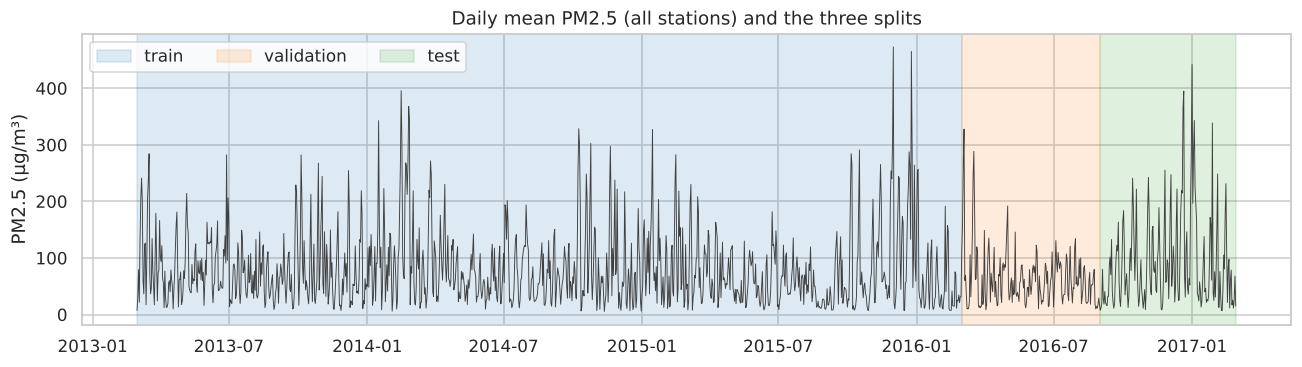

In [8]:
daily = df_clean.set_index("datetime")[TARGET].resample("D").mean()

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(daily.index, daily.values, lw=0.6, color="0.25")
for part, color, name in ((train, "tab:blue", "train"), (val, "tab:orange", "validation"), (test, "tab:green", "test")):
    ax.axvspan(part["datetime"].min(), part["datetime"].max(), color=color, alpha=0.15, label=name)
ax.set(title="Daily mean PM2.5 (all stations) and the three splits", ylabel="PM2.5 (µg/m³)")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

### 5.3 Is the target similar in each split?

In [9]:
summary = pd.DataFrame({name: part[TARGET].describe() for name, part in
                        (("train", train), ("validation", val), ("test", test))}).T.round(1)
summary["% hours > 150"] = [round((p[TARGET] > 150).mean() * 100, 1) for p in (train, val, test)]
summary

,count,mean,std,min,25%,50%,75%,max,% hours > 150
train,311599.0,80.3,80.2,2.0,21.0,56.0,113.0,999.0,15.3
validation,52337.0,64.3,59.7,3.0,22.0,49.0,86.0,474.0,7.1
test,51547.0,92.0,98.6,2.0,17.0,58.0,135.0,835.0,21.4


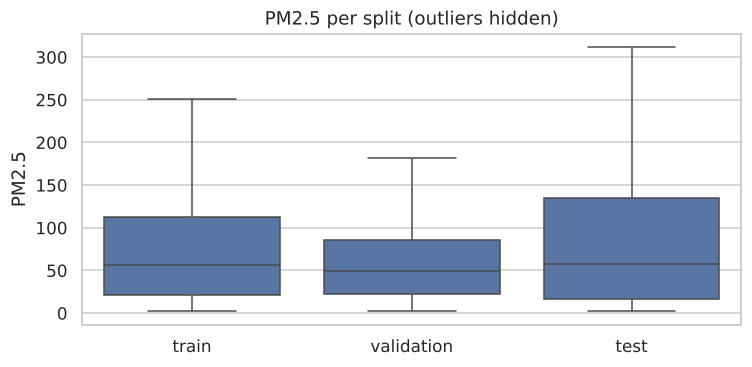

In [10]:
both = pd.concat([part.assign(split=name) for name, part in
                  (("train", train), ("validation", val), ("test", test))])
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(data=both, x="split", y=TARGET, showfliers=False, ax=ax)
ax.set(title="PM2.5 per split (outliers hidden)", xlabel="")
plt.tight_layout(); plt.show()

**What we see.** Validation (spring/summer) has lower PM2.5 than train; test (autumn/winter) has higher. So a model can look good on validation and worse on test just because of the season. We report both and explain the gap.

### 5.4 Missing values per split

In [11]:
cols = POLLUTANTS + WEATHER + ["wd"]
pd.DataFrame({name: part[cols].isna().mean() * 100 for name, part in
              (("train", train), ("validation", val), ("test", test))}).round(2)

,train,validation,test
PM2.5,1.28,1.24,1.11
PM10,4.34,0.93,0.84
SO2,1.50,1.06,0.88
NO2,2.13,1.16,1.00
CO,4.43,1.44,1.15
O3,2.09,1.50,1.62
TEMP,0.00,0.00,0.00
PRES,0.00,0.00,0.00
DEWP,0.00,0.00,0.00
RAIN,0.00,0.00,0.00


### 5.5 Which months each split covers

In [12]:
months = both.groupby(["split", both["datetime"].dt.month]).size().unstack(fill_value=0)
months = months.loc[["train", "validation", "test"]]
(months // 24 // 12).rename_axis(index="days per month")  # per station

datetime,1,2,3,4,5,6,7,8,9,10,11,12
days per month,,,,,,,,,,,,
train,93,85,93,90,93,90,93,93,90,93,90,93
validation,0,0,31,30,31,30,31,31,0,0,0,0
test,31,28,0,0,0,0,0,0,30,31,30,31


**What we see.** Train covers every month three times; validation is March–August; test is September–February. No month is missing from train, so the model sees every season before it is tested.

## 6. Leakage checks
Leakage = information from the validation or test period reaching the model during training. We check four things.
### 6.1 No overlap in time, no row in two splits
`check_no_leakage()` raises an error if a split overlaps another or a (station, hour) appears twice.

In [13]:
def check_no_leakage(train, val, test):
    """Raise an AssertionError if the splits overlap in time or lose/duplicate rows.

    Returns a small summary table (rows and date range per split).
    """
    assert train["datetime"].max() < val["datetime"].min(), "train overlaps validation"
    assert val["datetime"].max() < test["datetime"].min(), "validation overlaps test"

    keys = [set(zip(s["station"], s["datetime"])) for s in (train, val, test)]
    assert not (keys[0] & keys[1] or keys[0] & keys[2] or keys[1] & keys[2]), "a row is in two splits"

    return pd.DataFrame({
        "rows": [len(s) for s in (train, val, test)],
        "from": [s["datetime"].min() for s in (train, val, test)],
        "to": [s["datetime"].max() for s in (train, val, test)],
    }, index=["train", "validation", "test"])


check_no_leakage(train, val, test)

,rows,from,to
train,315648,2013-03-01,2016-02-29 23:00:00
validation,52992,2016-03-01,2016-08-31 23:00:00
test,52128,2016-09-01,2017-02-28 23:00:00


In [14]:
assert len(train) + len(val) + len(test) == len(df_clean), "rows were lost or duplicated"
print("All", len(df_clean), "rows are in exactly one split")

All 420768 rows are in exactly one split


### 6.2 Every station is cut at the same moment
If one station's test period started earlier, its "future" could sit in another station's training data.

In [15]:
per_station = pd.DataFrame({
    "train ends": train.groupby("station")["datetime"].max(),
    "val starts": val.groupby("station")["datetime"].min(),
    "val ends": val.groupby("station")["datetime"].max(),
    "test starts": test.groupby("station")["datetime"].min(),
})
assert per_station.nunique().eq(1).all(), "stations are cut at different times"
per_station.head(3)

,train ends,val starts,val ends,test starts
station,,,,
Aotizhongxin,2016-02-29 23:00:00,2016-03-01,2016-08-31 23:00:00,2016-09-01
Changping,2016-02-29 23:00:00,2016-03-01,2016-08-31 23:00:00,2016-09-01
Dingling,2016-02-29 23:00:00,2016-03-01,2016-08-31 23:00:00,2016-09-01


### 6.3 Scaling uses train only
Neural networks need scaled inputs. The mean and standard deviation must come from **train only**; otherwise the model learns something about the future (here: that the test winter is dirtier). The table shows how much the numbers move if we wrongly use all the data.

In [16]:
num = POLLUTANTS + WEATHER
compare = pd.DataFrame({
    "train mean": train[num].mean(), "all-data mean": df_clean[num].mean(),
    "train std": train[num].std(), "all-data std": df_clean[num].std(),
}).round(1)
compare["mean shift %"] = ((compare["all-data mean"] / compare["train mean"] - 1) * 100).round(1)
compare

,train mean,all-data mean,train std,all-data std,mean shift %
PM2.5,80.3,79.7,80.2,80.8,-0.7
PM10,106.0,104.8,91.4,92.1,-1.1
SO2,17.8,15.8,23.6,21.7,-11.2
NO2,51.2,50.6,35.0,35.1,-1.2
CO,1241.8,1230.4,1133.9,1159.7,-0.9
O3,57.1,57.2,56.1,56.2,0.2
TEMP,13.4,13.5,11.4,11.4,0.7
PRES,1010.6,1010.8,10.5,10.5,0.0
DEWP,2.4,2.5,13.9,13.8,4.2
RAIN,0.1,0.1,0.8,0.8,0.0


**What we see.** For most columns the shift is small (about 1%), but SO2 moves by about 11% because SO2 fell year after year. The rule is about fairness, not size: the test period must stay unseen.

**Decision.** The scaler is fitted on `train` and then only *applied* to validation and test (this goes in the training code, not here).

### 6.4 Targets near the split boundaries
The model predicts PM2.5 **6 hours ahead**. If we built the target on the whole table and then split, the last 6 training hours would get their targets from the first validation hours, which is leakage. So windows and targets are built **inside each split, per station**. Below: the last rows of train for one station, with the target built inside train only.

In [17]:
HORIZON = 6
one = train[train["station"] == train["station"].iloc[0]][["station", "datetime", TARGET]].copy()
one["target_6h"] = one[TARGET].shift(-HORIZON)
one.tail(HORIZON + 2)

,station,datetime,PM2.5,target_6h
26296,Aotizhongxin,2016-02-29 16:00:00,50.0,71.0
26297,Aotizhongxin,2016-02-29 17:00:00,59.0,64.0
26298,Aotizhongxin,2016-02-29 18:00:00,60.0,NaN
26299,Aotizhongxin,2016-02-29 19:00:00,59.0,NaN
26300,Aotizhongxin,2016-02-29 20:00:00,57.0,NaN
26301,Aotizhongxin,2016-02-29 21:00:00,64.0,NaN
26302,Aotizhongxin,2016-02-29 22:00:00,71.0,NaN
26303,Aotizhongxin,2016-02-29 23:00:00,64.0,NaN


**What we see.** The last 6 train hours have no target (NaN), because their future is in validation. They are dropped when we build training windows. We lose 6 h × 12 stations = 72 rows per boundary, a tiny price for a fair test.

### 6.5 Summary
- Splits are in time order, with no overlap and no lost rows.
- All 12 stations are cut at the same timestamps.
- Scaling statistics will come from train only.
- 6-hour targets are built inside each split, so no target crosses a boundary.

## 7. Save outputs
**Owner:** Experimentation · **Status:** done

`save_outputs()` writes the clean table to `data/interim/clean.csv` and the split dates to `configs/split.json`, so the baseline and model notebooks load the same data.

In [18]:
def save_outputs(df_clean, train_end, val_end,
                 data_path=Path("data/interim/clean.csv"), config_path=Path("configs/split.json")):
    """Save the cleaned table and the split dates so every later notebook uses the same ones."""
    data_path.parent.mkdir(parents=True, exist_ok=True)
    config_path.parent.mkdir(parents=True, exist_ok=True)
    df_clean.to_csv(data_path, index=False)
    config_path.write_text(json.dumps({"train_end": str(train_end), "val_end": str(val_end)}, indent=2))
    return data_path, config_path


save_outputs(df_clean, TRAIN_END, VAL_END)

(PosixPath('data/interim/clean.csv'), PosixPath('configs/split.json'))